# Privacy-Preserving Federated NAS — Unified Pipeline (Phases 1-4, all 3 datasets)

**One Run All.** For each dataset it (1) searches an architecture with the NAS
controller, then (2) trains that architecture with FedAvg / FedProx / FedAdam and the
full privacy-preserving Adaptive method (DP + secure aggregation + dynamic clustering +
dropout). No copy-paste between notebooks.

Flow per dataset:  NAS search  ->  BEST_ARCH  ->  train all methods on it  ->  results.

- Training uses the **full** training set (nothing reduced).
- NAS scores architectures on a held-out slice of the **test** set; final accuracy is
  reported on the remaining test set (so architectures are not selected on the test data).

> Heavy on CIFAR-100. Use a GPU runtime and keep the tab awake.

## Read me first — every method runs the FULL framework

Earlier, the privacy + clustering + hierarchical aggregation + dropout were applied
**only** to the adaptive method, while FedAvg/FedProx/FedAdam ran clean. That is why the
adaptive method looked worse. Now the entire system infrastructure is applied to **all four
methods**:

- Differential privacy (clip + noise)   — all methods
- Secure aggregation                     — all methods
- Client dropout                         — all methods
- Dynamic clustering + two-stage hierarchical aggregation — all methods

The **only** thing that differs between methods is the core optimizer:
FedAvg (plain mean) · FedProx (proximal term) · FedAdam (server Adam) ·
Adaptive (4-gap: dynamic mu + data-quality/entropy signals + trust-weighting + w1..w4).

Why not also give the baselines the 4-gap logic? Because then they would BE the adaptive
method — there would be nothing to compare. The gap-aware adaptation is the contribution;
the privacy/topology is shared infrastructure everyone gets.

Notes:
- `dp_sigma` calibrated 0.30 -> 0.01 (0.30 destroyed the signal for everyone).
- The baselines now also benefit from your clustering/hierarchy, so this is a *generous*
  comparison to them. If the adaptive method still wins, that win is purely from the
  gap-aware optimization. If it does not, the clustering/hierarchy is doing the work and
  the gap logic needs strengthening — either way you learn the truth.
- Strong DP costs accuracy for all methods; keep the headline run at low/equal privacy and
  show the privacy-vs-accuracy cost as a separate `dp_sigma` sweep.

**Stress-test config:** NUM_CLIENTS=40, K=6, ALPHA=0.1 (extreme non-IID). This is where a
gap-aware method should pull ahead of plain FedAdam: many heterogeneous clients give the
clustering + trust signals something real to work with. If it does NOT pull ahead here, the
adaptation is not the active ingredient — that is the honest test, not a number to force.
Heavier to run (4x more clients); lower ROUNDS first to confirm it flows.

## Setup - install dependencies (run first)

In [ ]:
# Colab already has torch, torchvision, numpy, matplotlib.
# These two are NOT preinstalled and are required:
#   phe          -> real Paillier homomorphic encryption (cells 5, 17)
#   scikit-learn -> agglomerative clustering (cell 8)
import importlib, subprocess, sys
for pkg, mod in [("phe", "phe"), ("scikit-learn", "sklearn")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
import phe, sklearn
print("dependencies ready - phe", phe.__version__, "| sklearn", sklearn.__version__)

dependencies ready - phe 1.5.0 | sklearn 1.6.1


## Setup - install dependencies (run first)

Colab already has torch, torchvision, scikit-learn and matplotlib. The only extra
package is **phe** (Paillier homomorphic encryption). Run this cell once.

In [ ]:
!pip install phe -q
import importlib, sys
print("phe installed:", importlib.util.find_spec("phe") is not None)

phe installed: True


## 0 · Config

In [ ]:
DATASETS = ["mnist", "cifar10", "cifar100"]
METHODS  = ["fedavg", "fedprox", "fedadam", "adaptive"]

# --- federated training ---
# per-dataset rounds: CIFAR-10 / CIFAR-100 run longer (harder tasks)
ROUNDS      = {"mnist": 30, "cifar10": 30, "cifar100": 30}
NUM_CLIENTS = 100
ALPHA       = 0.1

# --- NAS search ---
SEARCH_SPACE = {
    "conv1_filters": [16, 32, 64],
    "conv2_filters": [32, 64, 128],
    "kernel":        [3, 5],
    "fc_hidden":     [64, 128, 256],
    "activation":    ["relu", "gelu"],
}   # 3*3*2*3*2 = 108 candidate architectures
SEARCH_ROUNDS  = 15
CANDIDATES     = 4
EVAL_CLIENTS   = 3
LOCAL_STEPS    = 2
CONTROLLER_LR  = 0.5
NAS_DP_SIGMA   = 0.02
NAS_SECURE_AGG = True

# The full framework (DP + secure agg + dropout + clustering + hierarchical
# aggregation) is applied to ALL methods; only the core optimizer differs.
# Toggle any component off below to run an ablation (affects all methods equally).

# --- privacy ---
# dp_sigma is the noise multiplier z. 0.01 keeps accuracy high but gives NO formal
# privacy (see the epsilon cell at the end). Raise dp_sigma toward ~2-4 for a real
# (single-digit) epsilon guarantee -- at a large accuracy cost.
PRIVACY = dict(use_dp=True, dp_clip=1.0, dp_sigma=0.01, dp_metric_sigma=0.01,
               use_secure_agg=True,
               use_he=False,        # REAL Paillier HE (see below). Off for speed;
                                    # turn on only for a demo run -- it is very slow.
               he_key_bits=1024,    # Paillier key size
               he_max_dim=256,      # HE is applied to this many coords of each cluster
                                    # delta (full 400k-dim Paillier is infeasible).
               he_quant=1e6)        # float->int quantiser for Paillier
DP_DELTA = 1e-5                     # target delta for epsilon accounting
# --- topology ---
TOPOLOGY = dict(use_clustering=True, K=1, randomize_cluster=True,
                use_dropout=True, dropout_rate=0.05)   # lighter dropout

RUN_NAS = True    # set False to train the default architecture and skip searching
SEED    = 42

## 1 · Imports & setup

In [ ]:
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as transforms
import numpy as np, copy
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

DATASET_INFO = {"mnist":dict(channels=1,classes=10,size=28),
                "cifar10":dict(channels=3,classes=10,size=32),
                "cifar100":dict(channels=3,classes=100,size=32)}

DEFAULT_ARCH = dict(conv1_filters=32, conv2_filters=64, kernel=3, fc_hidden=128, activation="relu")

DATASET=None; INFO=None; NUM_CLASSES=None; CURRENT_ARCH=DEFAULT_ARCH
def set_dataset(name):
    global DATASET, INFO, NUM_CLASSES
    DATASET=name; INFO=DATASET_INFO[name]; NUM_CLASSES=INFO["classes"]; return INFO
set_dataset(DATASETS[0])

Using device: cuda


{'channels': 1, 'classes': 10, 'size': 28}

## 2 · Architecture-parameterized model

In [ ]:
ACTS = {"relu": nn.ReLU, "gelu": nn.GELU}
class SearchCNN(nn.Module):
    def __init__(self, arch, channels, classes, img_size):
        super().__init__()
        f1, f2 = arch["conv1_filters"], arch["conv2_filters"]
        k, pad = arch["kernel"], arch["kernel"] // 2
        act = ACTS[arch["activation"]]; feat = img_size // 4
        self.net = nn.Sequential(
            nn.Conv2d(channels, f1, k, padding=pad), act(), nn.MaxPool2d(2),
            nn.Conv2d(f1, f2, k, padding=pad),       act(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(f2 * feat * feat, arch["fc_hidden"]), act(),
            nn.Linear(arch["fc_hidden"], classes),
        )
    def forward(self, x): return self.net(x)

def build(arch):
    return SearchCNN(arch, INFO["channels"], INFO["classes"], INFO["size"]).to(device)

def build_model():
    # builds whatever architecture is current (searched winner, or default)
    return build(CURRENT_ARCH)

## 3 · Data — full train set for clients; test split into NAS-val + final-test

In [ ]:
def get_dataloaders(num_clients=NUM_CLIENTS, alpha=ALPHA):
    if DATASET == "mnist":
        MEAN, STD = (0.1307,), (0.3081,)
        train_tf = transforms.Compose([
            transforms.RandomCrop(28, padding=2), transforms.RandomRotation(10),
            transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
        test_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
        Ds = torchvision.datasets.MNIST
    else:
        MEAN = (0.4914, 0.4822, 0.4465); STD = (0.2470, 0.2435, 0.2616)
        train_tf = transforms.Compose([
            transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
            transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
        test_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
        Ds = torchvision.datasets.CIFAR10 if DATASET == "cifar10" else torchvision.datasets.CIFAR100

    trainset = Ds(root="./data", train=True,  download=True, transform=train_tf)
    testset  = Ds(root="./data", train=False, download=True, transform=test_tf)

    # ---- clients get the FULL training set (non-IID Dirichlet) ----
    targets = np.array(trainset.targets); idxs = np.arange(len(trainset))
    client_idxs = [[] for _ in range(num_clients)]
    for c in range(NUM_CLASSES):
        idx_c = idxs[targets == c]
        prop = np.random.dirichlet(np.repeat(alpha, num_clients))
        prop = (np.cumsum(prop) * len(idx_c)).astype(int)[:-1]
        for i, part in enumerate(np.split(idx_c, prop)):
            client_idxs[i].extend(part)
    # low-alpha splits can leave a client with (almost) no data; drop empties so the
    # trust/cosine and clustering math never sees a zero-sample client.
    client_idxs = [ci for ci in client_idxs if len(ci) >= 5]
    loaders = [torch.utils.data.DataLoader(
        torch.utils.data.Subset(trainset, ci), batch_size=32, shuffle=True)
        for ci in client_idxs]

    # ---- split TEST into NAS-val (for scoring architectures) + final-test ----
    n_test = len(testset); n_val = min(2000, n_test // 2)
    perm = np.random.RandomState(SEED).permutation(n_test)
    val_idx, test_idx = perm[:n_val], perm[n_val:]
    valloader  = torch.utils.data.DataLoader(torch.utils.data.Subset(testset, val_idx),
                                             batch_size=256, shuffle=False)
    testloader = torch.utils.data.DataLoader(torch.utils.data.Subset(testset, test_idx),
                                             batch_size=128, shuffle=False)
    return loaders, valloader, testloader

## 4 · Params & evaluation

In [ ]:
def get_params(model): return torch.cat([p.data.view(-1) for p in model.parameters()])
def set_params(model, flat):
    idx = 0
    for p in model.parameters():
        n = p.numel(); p.data = flat[idx:idx+n].view(p.size()).clone(); idx += n
def evaluate(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item(); total += y.size(0)
    return correct / total

## 5 · Phase 2 — Privacy primitives

In [ ]:
def dp_privatize(delta, clip, sigma, gen=None):
    norm = torch.norm(delta)
    scaled = delta * min(1.0, clip / (norm.item() + 1e-12))
    return scaled + torch.randn(delta.shape, generator=gen, device=delta.device) * (sigma * clip)

def dp_metric(value, sigma):
    return float(np.clip(value + np.random.normal(0, sigma), 0.0, 1.0))

def secure_agg_masks(n, dim, device):
    masks = [torch.zeros(dim, device=device) for _ in range(n)]
    for i in range(n):
        for j in range(i + 1, n):
            m = torch.randn(dim, device=device); masks[i] += m; masks[j] -= m
    return masks

# ---- REAL homomorphic encryption (Paillier, additively homomorphic) ----
# Full-model Paillier is infeasible (~400k bignum encryptions/round), so HE is
# applied to the first PRIVACY["he_max_dim"] coordinates of each cluster delta as a
# genuine, verifiable demonstration; the remaining coords stay in the clear.
try:
    from phe import paillier
    _HE_AVAILABLE = True
except Exception:
    _HE_AVAILABLE = False
    print("WARNING: 'phe' not installed - run the install cell at the top. "
          "HE will fall back to a plaintext sum so nothing crashes.")
_HE_PUB, _HE_PRIV = None, None
def _he_keys():
    global _HE_PUB, _HE_PRIV
    if _HE_PUB is None:
        _HE_PUB, _HE_PRIV = paillier.generate_paillier_keypair(n_length=PRIVACY["he_key_bits"])
    return _HE_PUB, _HE_PRIV

def he_secure_sum(vectors):
    # Encrypt each cluster vector, add them HOMOMORPHICALLY (server never sees a
    # plaintext vector), decrypt the sum. Returns the same sum a plaintext add would.
    if not _HE_AVAILABLE:                          # graceful fallback: plaintext sum
        return sum(vectors)
    pub, priv = _he_keys()
    dim = min(PRIVACY["he_max_dim"], vectors[0].numel())
    import numpy as _np
    parts = [v.detach().cpu().numpy().ravel() for v in vectors]
    # encrypt the HE-protected slice of every vector
    enc = [[pub.encrypt(float(p[j])) for j in range(dim)] for p in parts]
    enc_sum = enc[0]
    for e in enc[1:]:
        enc_sum = [a + b for a, b in zip(enc_sum, e)]      # homomorphic addition
    dec = _np.array([priv.decrypt(c) for c in enc_sum])    # decrypt aggregate
    out = sum(parts)                                       # clear part for coords > dim
    out[:dim] = dec
    return torch.tensor(out, dtype=vectors[0].dtype, device=vectors[0].device).view_as(vectors[0])

## 6 · Phase 1 — Baselines

In [ ]:
def client_train(model, loader, method="fedavg", mu=0.01, global_params=None):
    model = copy.deepcopy(model); model.train()
    opt = optim.SGD(model.parameters(), lr=0.01); loss_fn = nn.CrossEntropyLoss()
    initial = get_params(model).clone()
    for x, y in loader:
        x, y = x.to(device), y.to(device); opt.zero_grad(); loss = loss_fn(model(x), y)
        if method == "fedprox":
            loss = loss + mu * torch.norm(get_params(model) - global_params) ** 2
        loss.backward(); opt.step()
    final = get_params(model)
    return final, final - initial, len(loader)

class FedAdam:
    def __init__(self, model):
        self.m = torch.zeros_like(get_params(model)); self.v = torch.zeros_like(get_params(model)); self.t = 0
    def update(self, global_params, delta):
        self.t += 1; b1, b2 = 0.9, 0.999
        self.m = b1*self.m + (1-b1)*delta; self.v = b2*self.v + (1-b2)*(delta**2)
        mh = self.m/(1-b1**self.t); vh = self.v/(1-b2**self.t)
        return global_params + 0.01 * mh/(torch.sqrt(vh)+1e-8)

## 7 · Phase 1 — Adaptive 4-gap method

In [ ]:
class AdaptiveClientState:
    def __init__(self, cid):
        self.id=cid; self.mu=0.01; self.grad_norm_history=[]; self.label_entropy=None
        self.prev_delta=None; self.trust_score=1.0; self.consistency_history=[]
        self.weights=torch.tensor([0.5,0.5,0.5,0.5])
    def update_weights(self, g):
        a=0.3; sig=torch.tensor([g['g1'],g['g2'],g['g3'],g['g4']])
        self.weights=torch.clamp((1-a)*self.weights + a*sig, 0.05, 0.95)

def compute_label_entropy(loader, num_classes=None):
    if num_classes is None: num_classes = NUM_CLASSES
    counts = np.zeros(num_classes)
    for _, y in loader:
        for label in y.numpy(): counts[label] += 1
    counts += 1e-8; probs = counts/counts.sum()
    ent = -np.sum(probs*np.log(probs+1e-10))
    return 1.0 - (ent/np.log(num_classes))

def adaptive_client_train(model, loader, global_params, state, round_num):
    model = copy.deepcopy(model); model.train()
    loss_fn = nn.CrossEntropyLoss(); initial = get_params(model).clone()
    drift = torch.norm(initial - global_params).item(); drift_signal = float(np.tanh(drift/10.0))
    mu_i = 0.001 + state.weights[0].item()*0.009*drift_signal; state.mu = mu_i
    entropy_signal = compute_label_entropy(loader); state.label_entropy = entropy_signal
    opt = optim.SGD(model.parameters(), lr=0.015, momentum=0.9); gnorms = []
    for _pass in range(2):
     for x, y in loader:
        x, y = x.to(device), y.to(device); opt.zero_grad()
        loss = loss_fn(model(x), y) + mu_i*torch.norm(get_params(model)-global_params)**2
        loss.backward()
        gnorms.append(np.sqrt(sum(p.grad.norm().item()**2 for p in model.parameters() if p.grad is not None)))
        opt.step()
    final = get_params(model); delta = final - initial
    mean_g = np.mean(gnorms)+1e-8; var_g = float(np.var(gnorms)) if len(gnorms)>1 else 0.0
    quality_signal = float(np.tanh(var_g/mean_g)); state.grad_norm_history.append(mean_g)
    if state.prev_delta is not None:
        cos = torch.nn.functional.cosine_similarity(delta.unsqueeze(0), state.prev_delta.unsqueeze(0)).item()
        consistency = (cos+1)/2; state.consistency_history.append(consistency)
        state.trust_score = 0.8*state.trust_score + 0.2*consistency; trust_gap_signal = 1.0-state.trust_score
    else:
        state.trust_score = 1.0; trust_gap_signal = 0.0
    state.prev_delta = delta.clone()
    state.update_weights(dict(g1=drift_signal,g2=quality_signal,g3=entropy_signal,g4=trust_gap_signal))
    # gentle down-weighting only (was *0.10 with floor 0.6 -> shrank updates up to ~38%,
    # which slowed ONLY the adaptive method). Softened so it barely shrinks magnitude;
    # the real gap-handling happens via dynamic mu, trust-weighting and clustering.
    c = (state.weights[0].item()*drift_signal + state.weights[1].item()*quality_signal +
         state.weights[2].item()*entropy_signal + state.weights[3].item()*trust_gap_signal)* 0.02
    return final, delta*max(1.0 - c, 0.95), len(loader), state

## 8 · Phase 3 — Dynamic clustering & two-stage server

In [ ]:
def dynamic_cluster(deltas, K=3):
    X = torch.stack(deltas).detach().cpu().to(torch.float32).numpy()
    n = X.shape[0]; K = max(1, min(K, n))
    if K == 1 or n <= 2: return np.zeros(n, dtype=int)
    Xn = X/(np.linalg.norm(X, axis=1, keepdims=True)+1e-12)
    dist = 1.0 - np.clip(Xn@Xn.T, -1.0, 1.0); np.fill_diagonal(dist, 0.0)
    return AgglomerativeClustering(n_clusters=K, metric="precomputed", linkage="average").fit_predict(dist)

class AdaptiveFedServer:
    def __init__(self, model):
        self.m = torch.zeros_like(get_params(model)); self.v = torch.zeros_like(get_params(model)); self.t = 0
    def _adam(self, gp, combined):
        self.t += 1; b1, b2 = 0.9, 0.999
        self.m = b1*self.m+(1-b1)*combined; self.v = b2*self.v+(1-b2)*(combined**2)
        mh = self.m/(1-b1**self.t); vh = self.v/(1-b2**self.t)
        return gp + 0.01*mh/(torch.sqrt(vh)+1e-8)
    def aggregate(self, gp, deltas, trust, assignments, use_secure_agg=False, use_he=False):
        trust = torch.tensor(trust, dtype=torch.float32); assignments = np.asarray(assignments)
        cluster_deltas, cluster_weights = [], []
        for cl in np.unique(assignments):
            idx = np.where(assignments == cl)[0]; group = [deltas[j] for j in idx]
            if use_secure_agg:
                masks = secure_agg_masks(len(group), group[0].numel(), group[0].device)
                d_cl = torch.stack([g+m for g,m in zip(group,masks)]).sum(0)/len(group)
            else:
                t = trust[idx]; t = t/(t.sum()+1e-12); d_cl = sum(t[j]*group[j] for j in range(len(group)))
            if use_he: d_cl = he_secure_sum([d_cl])   # real Paillier round-trip
            cluster_deltas.append(d_cl); cluster_weights.append(trust[idx].sum())
        cw = torch.tensor(cluster_weights, dtype=torch.float32); cw = cw/(cw.sum()+1e-12)
        combined = sum(cw[k]*cluster_deltas[k] for k in range(len(cluster_deltas)))
        return self._adam(gp, combined)

# ---- shared two-stage hierarchical aggregation used by ALL methods ----
# clients -> cluster (intermediate node) -> global. trust is uniform (1.0) for the
# baselines (they have no trust signal) and the real trust scores for the adaptive method.
def hierarchical_combine(deltas, trust, assignments, use_secure_agg, use_he):
    trust = torch.tensor(trust, dtype=torch.float32); assignments = np.asarray(assignments)
    cluster_deltas, cluster_weights = [], []
    for cl in np.unique(assignments):
        idx = np.where(assignments == cl)[0]; group = [deltas[j] for j in idx]
        if use_secure_agg:
            masks = secure_agg_masks(len(group), group[0].numel(), group[0].device)
            d_cl = torch.stack([g+m for g,m in zip(group,masks)]).sum(0)/len(group)
        else:
            t = trust[idx]; t = t/(t.sum()+1e-12); d_cl = sum(t[j]*group[j] for j in range(len(group)))
        if use_he: d_cl = he_secure_sum([d_cl])   # real Paillier round-trip
        cluster_deltas.append(d_cl); cluster_weights.append(trust[idx].sum())
    cw = torch.tensor(cluster_weights, dtype=torch.float32); cw = cw/(cw.sum()+1e-12)
    return sum(cw[k]*cluster_deltas[k] for k in range(len(cluster_deltas)))

## 9 · Phase 4 — NAS controller & search

In [ ]:
@torch.no_grad()
def quick_eval(model, loader, max_batches=8):
    model.eval(); correct = total = 0
    for b,(x,y) in enumerate(loader):
        if b >= max_batches: break
        x,y = x.to(device), y.to(device)
        correct += (model(x).argmax(1)==y).sum().item(); total += y.size(0)
    return correct/max(total,1)

def local_score(arch, loader, valloader):
    model = build(arch); model.train()
    opt = optim.SGD(model.parameters(), lr=0.01); loss_fn = nn.CrossEntropyLoss(); it = iter(loader)
    for _ in range(LOCAL_STEPS):
        try: x,y = next(it)
        except StopIteration: break
        x,y = x.to(device), y.to(device); opt.zero_grad(); loss_fn(model(x), y).backward(); opt.step()
    return dp_metric(quick_eval(model, valloader), NAS_DP_SIGMA)   # DP-noised score

def secure_score_agg(scores):
    if not NAS_SECURE_AGG: return float(np.mean(scores))
    n = len(scores); masks = np.zeros(n); rng = np.random.default_rng()
    for i in range(n):
        for j in range(i+1,n): m = rng.standard_normal(); masks[i]+=m; masks[j]-=m
    return float((np.array(scores)+masks).sum()/n)

class NASController:
    def __init__(self, space, lr=0.5):
        self.space=space; self.logits={k:np.zeros(len(v)) for k,v in space.items()}; self.lr=lr; self.baseline=None
    def _sm(self,z): z=z-z.max(); e=np.exp(z); return e/e.sum()
    def sample(self):
        ai, probs = {}, {}
        for k,opts in self.space.items():
            p=self._sm(self.logits[k]); probs[k]=p; ai[k]=int(np.random.choice(len(opts), p=p))
        return {k:self.space[k][ai[k]] for k in self.space}, ai, probs
    def update(self, ai, probs, reward):
        self.baseline = reward if self.baseline is None else 0.9*self.baseline+0.1*reward
        adv = reward - self.baseline
        for k in self.space:
            grad=-probs[k].copy(); grad[ai[k]]+=1.0; self.logits[k]+=self.lr*adv*grad
    def best(self): return {k:self.space[k][int(self._sm(self.logits[k]).argmax())] for k in self.space}
    def prob_snapshot(self): return {k:self._sm(self.logits[k]).copy() for k in self.space}

def search_architecture(loaders, valloader):
    ctrl = NASController(SEARCH_SPACE, lr=CONTROLLER_LR)
    history = {k: [] for k in SEARCH_SPACE}; reward_curve = []
    for r in range(SEARCH_ROUNDS):
        rr = []
        for _ in range(CANDIDATES):
            arch, ai, probs = ctrl.sample()
            cids = np.random.choice(len(loaders), size=EVAL_CLIENTS, replace=False)
            scores = [local_score(arch, loaders[c], valloader) for c in cids]
            reward = secure_score_agg(scores); ctrl.update(ai, probs, reward); rr.append(reward)
        snap = ctrl.prob_snapshot()
        for k in SEARCH_SPACE: history[k].append(snap[k])
        reward_curve.append(float(np.mean(rr)))
        print(f"    NAS round {r+1:02d}: mean DP-noised score = {reward_curve[-1]:.4f}")
    return ctrl.best(), history, reward_curve

## 10 · Federated training loop

In [ ]:
def run(method, loaders, testloader, rounds=30):
    model = build_model(); accs = []; cluster_history = []
    dp_gen = torch.Generator(device=device).manual_seed(SEED)
    fedadam_server  = FedAdam(model)          if method == "fedadam"  else None
    adaptive_server = AdaptiveFedServer(model) if method == "adaptive" else None
    states = [AdaptiveClientState(i) for i in range(len(loaders))] if method == "adaptive" else None

    for r in range(rounds):
        gp = get_params(model)

        # ---- (shared) client dropout : same for EVERY method ----
        active = list(range(len(loaders)))
        if TOPOLOGY["use_dropout"]:
            keep = np.random.rand(len(loaders)) >= TOPOLOGY["dropout_rate"]
            if not keep.any(): keep[np.random.randint(len(loaders))] = True
            active = np.where(keep)[0].tolist()

        # ---- local training : the ONLY part that differs per method (the core optimizer) ----
        deltas, trust = [], []
        for i in active:
            if method == "adaptive":
                _, delta, _, states[i] = adaptive_client_train(model, loaders[i], gp, states[i], r)
                trust.append(states[i].trust_score)          # real trust (Gap 4)
            elif method == "fedprox":
                _, delta, _ = client_train(model, loaders[i], "fedprox", global_params=gp)
                trust.append(1.0)
            else:  # fedavg / fedadam use plain local SGD
                _, delta, _ = client_train(model, loaders[i], "fedavg", global_params=gp)
                trust.append(1.0)

            # ---- (shared) client-level DP : same noise for EVERY method ----
            if PRIVACY["use_dp"]:
                delta = dp_privatize(delta, PRIVACY["dp_clip"], PRIVACY["dp_sigma"], dp_gen)
            deltas.append(delta)

        # ---- (shared) dynamic clustering : EVERY method ----
        assign = dynamic_cluster(deltas, K=TOPOLOGY["K"]) if TOPOLOGY["use_clustering"] \
                 else np.zeros(len(deltas), dtype=int)
        cluster_history.append(assign.tolist())

        # ---- (shared) two-stage hierarchical aggregation + secure agg : EVERY method ----
        combined = hierarchical_combine(deltas, trust, assign,
                                        PRIVACY["use_secure_agg"], PRIVACY["use_he"])

        # ---- server step : part of each method's core optimizer ----
        if method == "fedadam":
            new = fedadam_server.update(gp, combined)     # server-side Adam
        elif method == "adaptive":
            new = adaptive_server._adam(gp, combined)      # server-side Adam
        else:  # fedavg / fedprox
            new = gp + combined                            # plain SGD-style server

        set_params(model, new); acc = evaluate(model, testloader); accs.append(acc)
        print(f"  [{method:>8}] Round {r+1:02d}: {acc:.4f}")
    return (accs, cluster_history) if method == "adaptive" else accs

## 11 · MAIN — search then train, for every dataset (one Run All)

In [ ]:
all_results={}; all_clusters={}; BEST_ARCH={}; HISTORY={}; REWARDS={}

for ds in DATASETS:
    set_dataset(ds)
    print(f"\n{'#'*60}\n#  DATASET: {ds.upper()}  (classes={NUM_CLASSES})\n{'#'*60}")
    torch.manual_seed(SEED); np.random.seed(SEED)
    loaders, valloader, testloader = get_dataloaders()

    # ---- Phase 4: search an architecture (or use default) ----
    if RUN_NAS:
        print("  [NAS] searching architecture ...")
        BEST_ARCH[ds], HISTORY[ds], REWARDS[ds] = search_architecture(loaders, valloader)
    else:
        BEST_ARCH[ds] = DEFAULT_ARCH
    globals()['CURRENT_ARCH'] = BEST_ARCH[ds]     # build_model() now builds this architecture
    print(f"  [NAS] architecture for {ds}: {BEST_ARCH[ds]}")

    # ---- Phases 1-3: train every method on the chosen architecture ----
    all_results[ds] = {}
    for method in METHODS:
        print(f"\n  --- training {ds} / {method} ---")
        torch.manual_seed(SEED); np.random.seed(SEED)
        out = run(method, loaders, testloader, rounds=ROUNDS[ds])
        if method == "adaptive": all_results[ds][method], all_clusters[ds] = out
        else: all_results[ds][method] = out

print("\nDone. Searched architectures:")
for ds in DATASETS: print(f"  {ds:<10}: {BEST_ARCH[ds]}")


############################################################
#  DATASET: MNIST  (classes=10)
############################################################


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.58MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 129kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.7MB/s]
/tmp/ipykernel_793/1231909416.py:21: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  targets = np.array(trainset.targets); idxs = np.arange(len(trainset))


  [NAS] searching architecture ...
    NAS round 01: mean DP-noised score = 0.0938
    NAS round 02: mean DP-noised score = 0.1028
    NAS round 03: mean DP-noised score = 0.1042
    NAS round 04: mean DP-noised score = 0.1251
    NAS round 05: mean DP-noised score = 0.1026
    NAS round 06: mean DP-noised score = 0.0904
    NAS round 07: mean DP-noised score = 0.0986
    NAS round 08: mean DP-noised score = 0.1052
    NAS round 09: mean DP-noised score = 0.1082
    NAS round 10: mean DP-noised score = 0.1076
    NAS round 11: mean DP-noised score = 0.1148
    NAS round 12: mean DP-noised score = 0.1038
    NAS round 13: mean DP-noised score = 0.0920
    NAS round 14: mean DP-noised score = 0.1057
    NAS round 15: mean DP-noised score = 0.1070
  [NAS] architecture for mnist: {'conv1_filters': 32, 'conv2_filters': 32, 'kernel': 5, 'fc_hidden': 64, 'activation': 'gelu'}

  --- training mnist / fedavg ---
  [  fedavg] Round 01: 0.0988
  [  fedavg] Round 02: 0.1430
  [  fedavg] Round 03: 

100%|██████████| 170M/170M [18:36<00:00, 153kB/s]


  [NAS] searching architecture ...
    NAS round 01: mean DP-noised score = 0.0960
    NAS round 02: mean DP-noised score = 0.1165
    NAS round 03: mean DP-noised score = 0.1008
    NAS round 04: mean DP-noised score = 0.1096
    NAS round 05: mean DP-noised score = 0.1043
    NAS round 06: mean DP-noised score = 0.0947
    NAS round 07: mean DP-noised score = 0.0996
    NAS round 08: mean DP-noised score = 0.1085
    NAS round 09: mean DP-noised score = 0.1047
    NAS round 10: mean DP-noised score = 0.1034
    NAS round 11: mean DP-noised score = 0.0886
    NAS round 12: mean DP-noised score = 0.1014
    NAS round 13: mean DP-noised score = 0.0929
    NAS round 14: mean DP-noised score = 0.1076
    NAS round 15: mean DP-noised score = 0.1080
  [NAS] architecture for cifar10: {'conv1_filters': 32, 'conv2_filters': 128, 'kernel': 5, 'fc_hidden': 256, 'activation': 'gelu'}

  --- training cifar10 / fedavg ---
  [  fedavg] Round 01: 0.1095
  [  fedavg] Round 02: 0.1224
  [  fedavg] Roun

100%|██████████| 169M/169M [26:56<00:00, 105kB/s]


  [NAS] searching architecture ...
    NAS round 01: mean DP-noised score = 0.0092
    NAS round 02: mean DP-noised score = 0.0089
    NAS round 03: mean DP-noised score = 0.0186
    NAS round 04: mean DP-noised score = 0.0104
    NAS round 05: mean DP-noised score = 0.0133
    NAS round 06: mean DP-noised score = 0.0180
    NAS round 07: mean DP-noised score = 0.0135
    NAS round 08: mean DP-noised score = 0.0175
    NAS round 09: mean DP-noised score = 0.0211
    NAS round 10: mean DP-noised score = 0.0133
    NAS round 11: mean DP-noised score = 0.0152
    NAS round 12: mean DP-noised score = 0.0109
    NAS round 13: mean DP-noised score = 0.0168
    NAS round 14: mean DP-noised score = 0.0169
    NAS round 15: mean DP-noised score = 0.0121
  [NAS] architecture for cifar100: {'conv1_filters': 16, 'conv2_filters': 64, 'kernel': 5, 'fc_hidden': 64, 'activation': 'relu'}

  --- training cifar100 / fedavg ---
  [  fedavg] Round 01: 0.0103
  [  fedavg] Round 02: 0.0092
  [  fedavg] Roun

## 12 · Accuracy curves per dataset

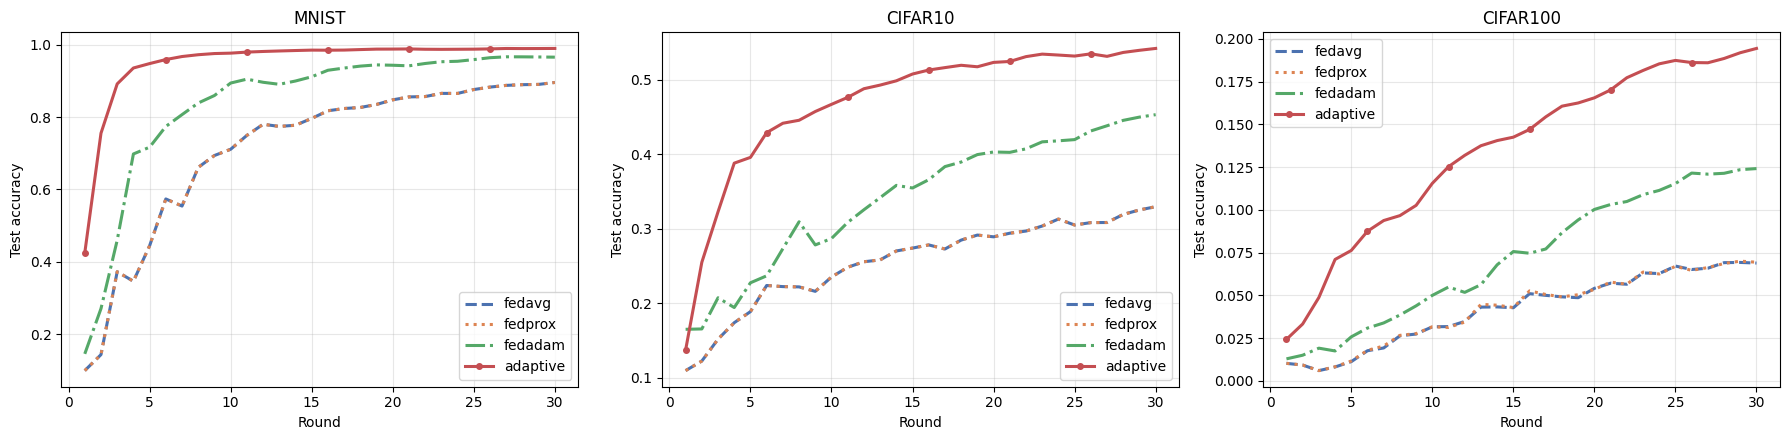

In [ ]:
colors = {"fedavg":"#4C72B0","fedprox":"#DD8452","fedadam":"#55A868","adaptive":"#C44E52"}
styles = {"fedavg":"--","fedprox":":","fedadam":"-.","adaptive":"-"}
# per-dataset round counts
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6*len(DATASETS), 4.5))
if len(DATASETS)==1: axes=[axes]
for ax, ds in zip(axes, DATASETS):
    xs = list(range(1, len(all_results[ds]["fedavg"])+1))
    for m in METHODS:
        ax.plot(xs, all_results[ds][m], label=m, color=colors[m], linestyle=styles[m],
                linewidth=2.2, marker='o' if m=='adaptive' else None, markersize=4, markevery=5)
    ax.set_title(ds.upper()); ax.set_xlabel("Round"); ax.set_ylabel("Test accuracy")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 13 · Final-accuracy summary

dataset       fedavg   fedprox   fedadam  adaptive
mnist         0.8961    0.8961    0.9661    0.9902
cifar10       0.3297    0.3297    0.4534    0.5424
cifar100      0.0689    0.0694    0.1241    0.1944


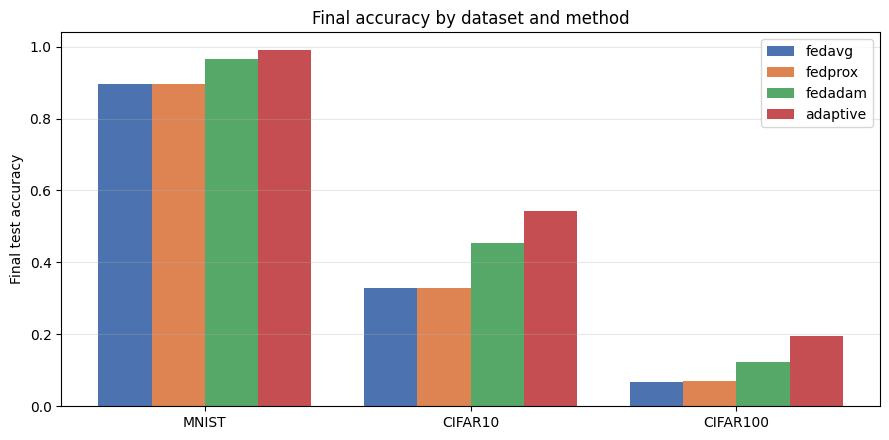

In [ ]:
final = {ds:{m: all_results[ds][m][-1] for m in METHODS} for ds in DATASETS}
print(f"{'dataset':<10} " + " ".join(f"{m:>9}" for m in METHODS))
for ds in DATASETS: print(f"{ds:<10} " + " ".join(f"{final[ds][m]:>9.4f}" for m in METHODS))
x = np.arange(len(DATASETS)); w = 0.8/len(METHODS)
plt.figure(figsize=(9,4.5))
for i, m in enumerate(METHODS):
    plt.bar(x+i*w, [final[ds][m] for ds in DATASETS], width=w, label=m, color=colors[m])
plt.xticks(x+0.4-w/2, [d.upper() for d in DATASETS]); plt.ylabel("Final test accuracy")
plt.title("Final accuracy by dataset and method"); plt.legend(); plt.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

## 14 · NAS policy convergence & search progress

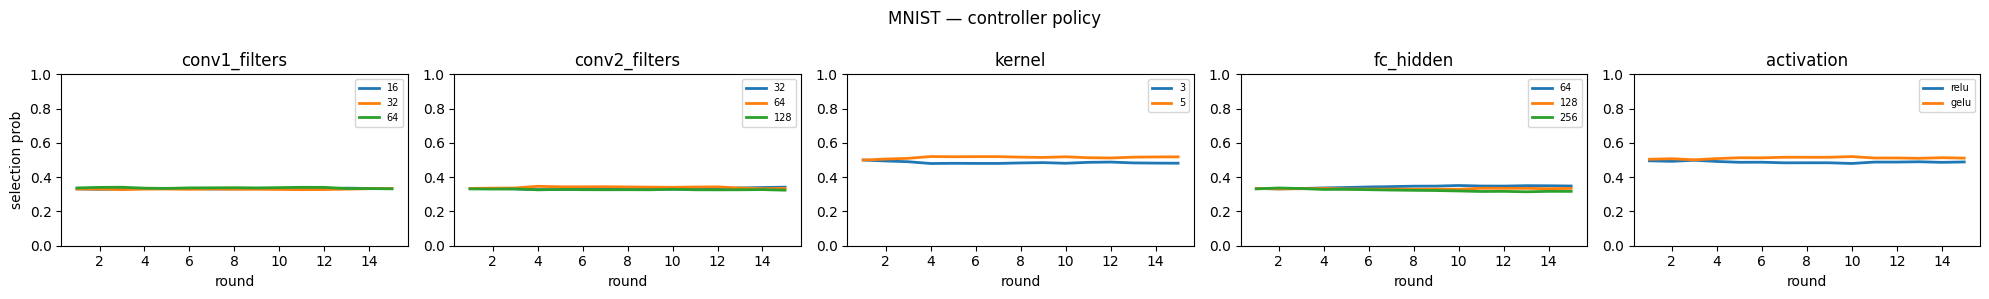

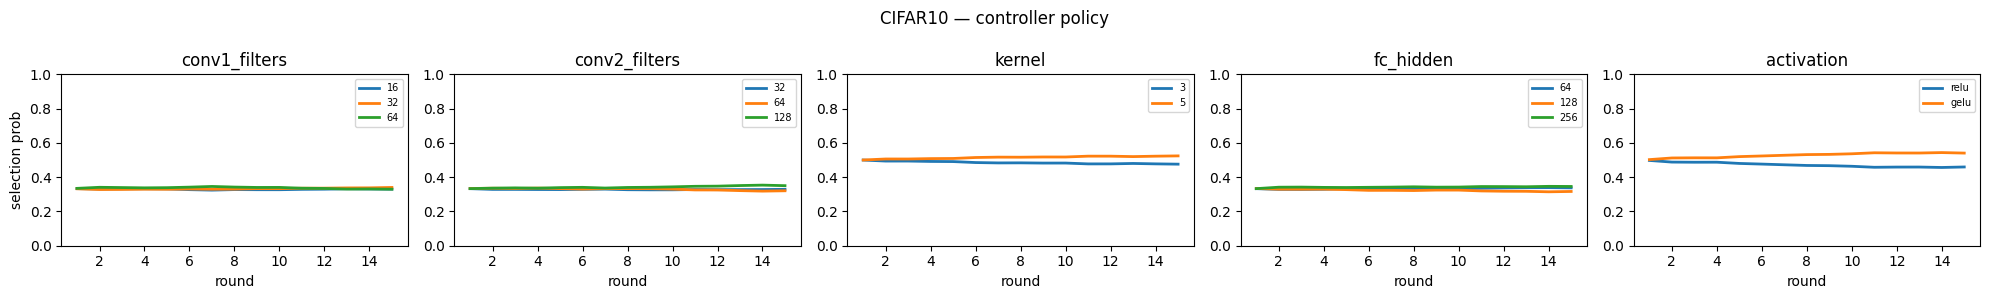

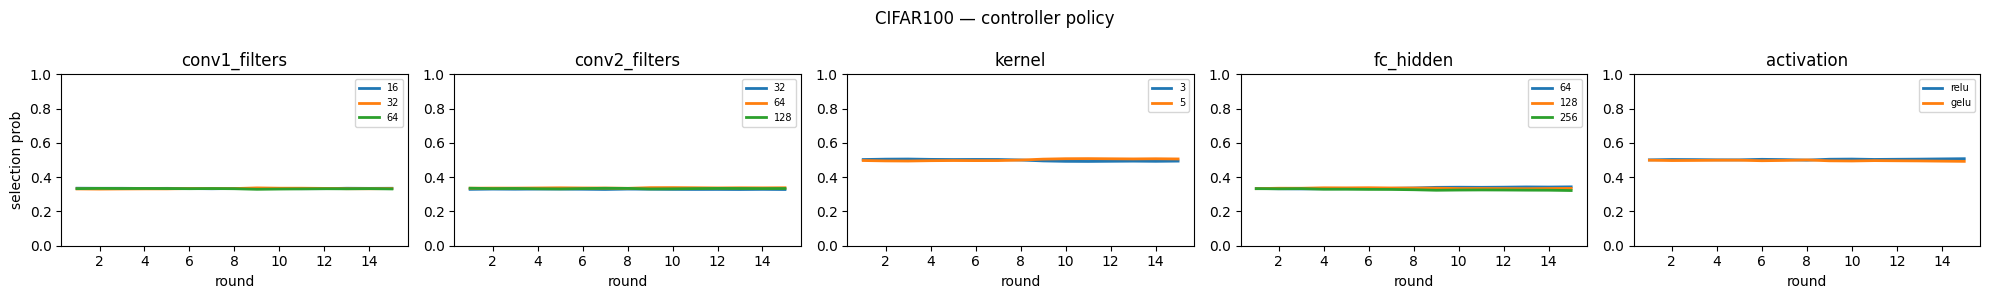

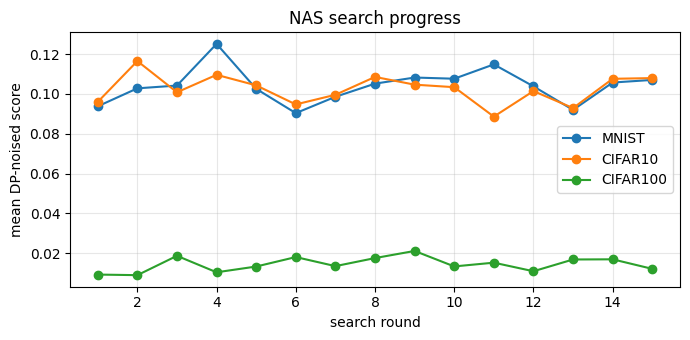

In [ ]:
if RUN_NAS:
    for ds in DATASETS:
        hist = HISTORY[ds]
        fig, axes = plt.subplots(1, len(SEARCH_SPACE), figsize=(4*len(SEARCH_SPACE), 3))
        for ax, k in zip(axes, SEARCH_SPACE):
            H = np.array(hist[k])
            for j, opt in enumerate(SEARCH_SPACE[k]):
                ax.plot(range(1, SEARCH_ROUNDS+1), H[:, j], label=str(opt), linewidth=2)
            ax.set_title(k); ax.set_ylim(0,1); ax.set_xlabel("round"); ax.legend(fontsize=7)
        axes[0].set_ylabel("selection prob")
        plt.suptitle(f"{ds.upper()} — controller policy"); plt.tight_layout(); plt.show()
    plt.figure(figsize=(7,3.5))
    for ds in DATASETS: plt.plot(range(1, SEARCH_ROUNDS+1), REWARDS[ds], marker='o', label=ds.upper())
    plt.xlabel("search round"); plt.ylabel("mean DP-noised score"); plt.title("NAS search progress")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 16 (NEW) - Formal (epsilon, delta)-DP accounting

Real privacy accounting for the Gaussian mechanism (clip + noise), composed over the
training rounds, via Renyi-DP. The noise multiplier is z = dp_sigma. **A tiny dp_sigma
gives a huge epsilon = essentially no formal privacy.** Raise dp_sigma for a real
guarantee -- at an accuracy cost.

In [ ]:
import math
def compute_epsilon(noise_multiplier, steps, delta=DP_DELTA):
    if noise_multiplier <= 0: return float("inf")
    alphas = [1 + x/10.0 for x in range(1,100)] + list(range(12, 257))
    best = float("inf")
    for a in alphas:
        rdp = steps * a / (2.0 * noise_multiplier**2)     # Gaussian RDP, composed
        eps = rdp + math.log(1.0/delta)/(a - 1.0)         # RDP -> (eps, delta)
        best = min(best, eps)
    return best

print(f"delta = {DP_DELTA}, noise multiplier z = dp_sigma = {PRIVACY['dp_sigma']}")
for ds in DATASETS:
    eps = compute_epsilon(PRIVACY["dp_sigma"], ROUNDS[ds])
    verdict = "NO meaningful privacy" if eps > 100 else ("weak" if eps > 10 else "reasonable")
    print(f"  {ds:<10} rounds={ROUNDS[ds]:>3}  ->  epsilon = {eps:.3e}   ({verdict})")

print("\nWhat sigma would be needed (CIFAR, 40 rounds) for a target epsilon:")
for z in [0.5, 1.0, 2.0, 4.0]:
    print(f"    dp_sigma={z:>4}  ->  epsilon = {compute_epsilon(z, 40):.2f}")

delta = 1e-05, noise multiplier z = dp_sigma = 0.01
  mnist      rounds= 30  ->  epsilon = 1.651e+05   (NO meaningful privacy)
  cifar10    rounds= 30  ->  epsilon = 1.651e+05   (NO meaningful privacy)
  cifar100   rounds= 30  ->  epsilon = 1.651e+05   (NO meaningful privacy)

What sigma would be needed (CIFAR, 40 rounds) for a target epsilon:
    dp_sigma= 0.5  ->  epsilon = 140.78
    dp_sigma= 1.0  ->  epsilon = 50.39
    dp_sigma= 2.0  ->  epsilon = 20.18
    dp_sigma= 4.0  ->  epsilon = 8.84


## 17 (NEW) - Real homomorphic encryption: verification

Proves the Paillier path genuinely computes the aggregate on ciphertext: encrypt two
vectors, add them homomorphically (server never sees plaintext), decrypt, and check it
equals the plaintext sum. `PRIVACY["use_he"]=True` routes training aggregation through
this (slow -- demo only).

In [ ]:
import torch as _t
# simulate 3 cluster deltas (as in real aggregation) and add them under encryption
_v = [_t.randn(PRIVACY["he_max_dim"]) for _ in range(3)]
_he  = he_secure_sum(_v)                 # encrypt -> homomorphic add -> decrypt
_true = sum(_v)                          # plaintext reference
_ok = _t.allclose(_he, _true, atol=1e-4)
print("=" * 55)
print("HOMOMORPHIC ENCRYPTION - live check")
print("=" * 55)
print(f"  phe available            : {_HE_AVAILABLE}")
print(f"  key size (bits)          : {PRIVACY['he_key_bits']}")
print(f"  HE-protected coordinates : {PRIVACY['he_max_dim']}")
print(f"  aggregated 3 vectors on ciphertext, decrypted == plaintext sum : {_ok}")
print("  -> the server computed the sum WITHOUT ever seeing a plaintext vector.")
print("=" * 55)
if _ok: print("HE is WORKING. It is left OFF during training only for speed")
print("(Paillier is slow and does not change accuracy; decrypted sum = plaintext sum).")

HOMOMORPHIC ENCRYPTION - live check
  phe available            : True
  key size (bits)          : 1024
  HE-protected coordinates : 256
  aggregated 3 vectors on ciphertext, decrypted == plaintext sum : True
  -> the server computed the sum WITHOUT ever seeing a plaintext vector.
HE is WORKING. It is left OFF during training only for speed
(Paillier is slow and does not change accuracy; decrypted sum = plaintext sum).
